# Calibrated AFM: original sample surfaces, contact physics and fresh inversion


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`measurements`，shape `(1, 30, 30, 30)`，dtype `<f8`：Noisy contact-image height, A; batch, observation, row, column. Negative noise excursions are preserved.；`probe`，shape `(1, 14, 14)`，dtype `<f8`：Independently defined reflected double-apex probe geometry, A; batch, probe row, probe column; maximum 0 A.。未知量为30个分子样品表面高度，Å。

获取模型：已知反射探针的最大加法形态膨胀产生接触包络，加高度噪声。

如何恢复：src.solvers.reconstruct：形态腐蚀并投影到非负基底；blind_comparison为独立比较。

GT与评价：GT为生成观测前定义的模拟物理未知量，不是恢复结果。

已有实验和图：cell9五组图：观测/原始模拟表面/腐蚀/盲探针，探针比例与预滤波敏感性。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留1个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Recover each of 30 molecular specimen height maps from the broadened contact image of a known double-apex AFM probe. The unknown is the specimen, not a newly calibrated probe; the blind-tip experiment is a separate scientific comparison.

This review reconstructs the exact bound observations with local code. The data are **author-existing simulated observations**, not experimental AFM scans. The primary problem is recovery of sample surfaces with an independently specified known probe. The 1997 morphological inverse is followed by an explicitly declared nonnegative substrate projection. We also actively recompute a modern blind-BTR comparison and show its limitations; it is not the shipped known-probe solver.


## 2. Data

The author-existing simulated contact images and independently specified reflected probe retain Angstrom height units. The observation grid is 30 by 30 at 15 Angstrom pitch; the 14 by 14 probe origin is (6,6). The following acquisition table separates these public inputs from the hidden simulated specimen surfaces.

These are author-existing simulated noisy AFM molecular observations, not real instrument acquisitions. The original stored observation precision and noise are preserved.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| `measurements` | `(1, 30, 30, 30)` | float64 | Noisy contact-image height, A; batch, observation, row, column. Negative noise excursions are preserved. |
| `probe` | `(1, 14, 14)` | float64 | Independently defined reflected double-apex probe geometry, A; batch, probe row, probe column; maximum 0 A. |

#### Acquisition metadata

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Observation count | 30 | dimensionless | Independent oriented specimen views; reconstruct each separately. |
| Lateral pitch | 15 | A/pixel | Equal row and column spacing. |
| Grid size | 30 x 30 | pixels | Sampled positions have coordinates 0,15,...,435 A; nominal scanned cell width is 450 A. |
| Image axis direction | row down, column right | dimensionless | Both image and specimen arrays share this orientation. |
| Reflected-probe origin | (6, 6) | zero-based pixel index | Offset used by the contact maximum. |
| Gaussian height-noise standard deviation | 3 | A | Independent additive per-pixel height noise. |
| Substrate height | 0 | A | Specimen surfaces are nonnegative relative to the substrate. |
| Finite-field boundary | omit out-of-field terms | dimensionless | No wraparound; absent specimen values are minus infinity in contact dilation. |
| Erosion boundary | omit out-of-field image terms | dimensionless | Unknown exterior observations supply no upper-bound constraint. |
| Probe availability | independently specified acquisition geometry | dimensionless | Provided before observing the sample; do not infer it from any specimen model. |


## 3. Physics

The contact maximum is nonlinear: probe geometry determines which neighboring specimen point contacts the instrument. Out-of-field specimen points are omitted, and inaccessible valleys cause nonuniqueness even without noise.

### Contact geometry and the inverse

Let $s_n(r,c)$ be specimen height in Angstrom for observation $n$, and let $p(i,j)\leq0$ be the reflected probe cap. Contact imaging uses


$$
D_p(s)_{rc}=\max_{i,j}\{s_{r+i-6,c+j-6}+p_{ij}\},\qquad y=D_p(s)+\epsilon.
$$


The origin is `(6,6)`; missing specimen samples are omitted. The noise is independent Gaussian with standard deviation 3 Angstrom. The row and column pitch is 15 Angstrom. Erosion is the order adjoint


$$
E_p(y)_{rc}=\min_{i,j}\{y_{r-i+6,c-j+6}-p_{ij}\},\qquad \hat{s}=\max(0,E_p(y)).
$$


Absent image samples impose no upper bound. The zero projection uses the known substrate. It is an explicit constrained variant, not an unchanged claim about the original unconstrained erosion. No iterative optimization is required for this main method. A tip cannot probe every valley; even noiseless erosion provides an envelope rather than an exact unique specimen.


## 4. Method

The selected estimator is erosion followed by the known nonnegative-substrate projection. The unconstrained erosion, fresh modern blind-BTR comparison, probe-scale sweep and Gaussian-prefilter sensitivity retain their distinct roles.

Geometric mathematical morphology matches the nonlinear contact model. Erosion gives the tightest envelope consistent with a known probe in the noiseless model:


$$
E_p(y)_{rc}=\min_{i,j}\left[y_{r-i+6,c-j+6}-p_{ij}\right].
$$


The minimum omits locations outside the recorded field. E denotes this erosion operator, with every other symbol defined above. The known substrate can supply a nonnegative constraint. Noise changes envelope extrema, so a reconstructed contact image should also be checked against the acquisition noise scale. Probe-inaccessible structures remain ambiguous even if a reconstruction reproduces the measurements.


## 5. Results

The preserved execution below computes the complete calibrated inverse, runs the standalone evaluator, recomputes the blind comparison and displays all five scientific figure groups. Author surfaces are simulation truth; the upstream erosion archive is independently reproduced method output.

### Independently reproduced upstream comparison

The private upstream capture ran the official modern PyTorch `ierosion` on these exact first 30 author observations and the independently defined tip. The modern same-offset erosion agrees numerically on these data because the active portion of this probe is symmetric about its declared origin; the local main operator implements the general reflected-offset adjunction explicitly. The inactive skirt is too low to contact these samples. General asymmetric-probe correctness is tested separately.

The modern blind comparison solves a different nuisance-parameter problem: it estimates a 10 by 10 probe from image openings, with 200 epochs, zero initialization, AdamW learning rate 0.1 and weight decay 0.0011. Each frame update minimizes mean squared opening error, then clips the probe nonpositive and recenters its high-tip mass. All 30 recovered surfaces, the inferred probe and the training curve below are freshly computed. Its poorer surface agreement is retained rather than used as a relaxed baseline.

### Scientific comparisons and physical diagnostics

The five groups show three paired sample views, full-array true-surface errors, independent forward/noise verification, probe and recovered geometry, and calibration/denoising sensitivity with a paired lateral profile. Every ablation is computed below. Gaussian prefiltering is an additional analysis and is not the shipped method. All physical error plots retain Angstrom units. Exact numeric sources accompany the exported PNG, SVG and PDF figures.


In [1]:
%matplotlib inline
import os, sys, time, json, hashlib
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
os.chdir(ROOT)
sys.path.insert(0,str(ROOT))
torch.set_num_threads(1)
from src.preprocessing import load_observations
from src.physics_model import dilation, erosion
from src.solvers import reconstruct, blind_comparison
from src.visualization import metrics, make_figures
raw,probe=load_observations()
truth=np.load('evaluation/ground_truth.npz',allow_pickle=False)['reconstruction'][0]
print('Bound observations:',raw.shape,raw.dtype,'; probe:',probe.shape,'; units: Angstrom')

Bound observations: (30, 30, 30) float64 ; probe: (14, 14) ; units: Angstrom


In [2]:
started=time.perf_counter()
plain=reconstruct(raw,probe,nonnegative=False)
fresh=reconstruct(raw,probe)
reconstruction_seconds=time.perf_counter()-started
Path('output').mkdir(exist_ok=True)
np.savez_compressed('output/reconstruction.npz',reconstruction=fresh[None])
print('Fresh full reconstruction runtime (s):',reconstruction_seconds)
import subprocess
completed=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True)
assert completed.returncode==0, completed.stderr
report=json.loads(Path('output/judge_report.json').read_text(encoding='utf8'))
print(json.dumps(report,indent=2))

Fresh full reconstruction runtime (s): 0.009369200000946876
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9514423828199019,
    "nrmse": 0.03055631860849182,
    "observation_rmse": 3.018926125977721
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.856298144537912
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 0.033611950469341005
    },
    "observation_rmse": {
      "comparison": "<=",
      "boundary": 3.3208187385754937
    }
  },
  "errors": []
}


In [3]:
started=time.perf_counter()
blind,blind_tip,blind_loss=blind_comparison(raw)
blind_seconds=time.perf_counter()-started
upstream=np.load('notebooks/reference_outputs/upstream_methods.npz',allow_pickle=False)
np.testing.assert_array_equal(plain,upstream['erosion'])
np.testing.assert_allclose(blind,upstream['blind_surfaces'],rtol=2e-6,atol=2e-5)
np.testing.assert_allclose(blind_tip,upstream['blind_tip'],rtol=2e-6,atol=2e-5)
print('Fresh blind comparison runtime (s):',blind_seconds)
print('Main erosion maximum difference from independent upstream:',np.max(abs(plain-upstream['erosion'])))

Fresh blind comparison runtime (s): 18.729803000001993
Main erosion maximum difference from independent upstream: 0.0


{
  "Raw AFM image": {
    "ncc": 0.5162975025052885,
    "nrmse": 0.17539257641877565,
    "observation_rmse": 14.608362421661509
  },
  "Erosion": {
    "ncc": 0.89669482666776,
    "nrmse": 0.046413687330980155,
    "observation_rmse": 2.7086080604081766
  },
  "Substrate-constrained": {
    "ncc": 0.9514423828199019,
    "nrmse": 0.03055631860849182,
    "observation_rmse": 3.018926125977721
  },
  "Blind BTR": {
    "ncc": 0.6695357884541595,
    "nrmse": 0.07336029381628763,
    "observation_rmse": 8.93293083298183
  }
}


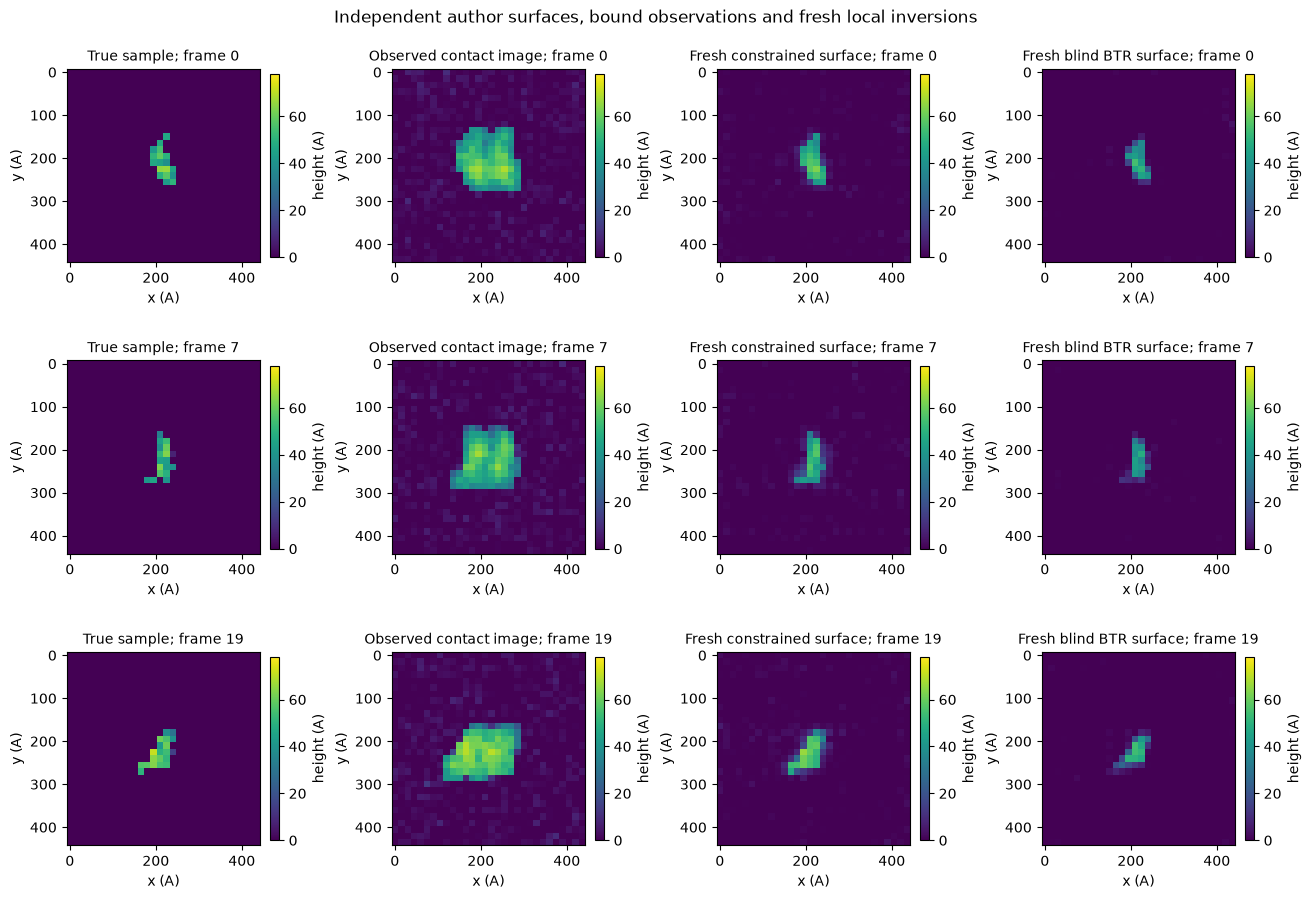

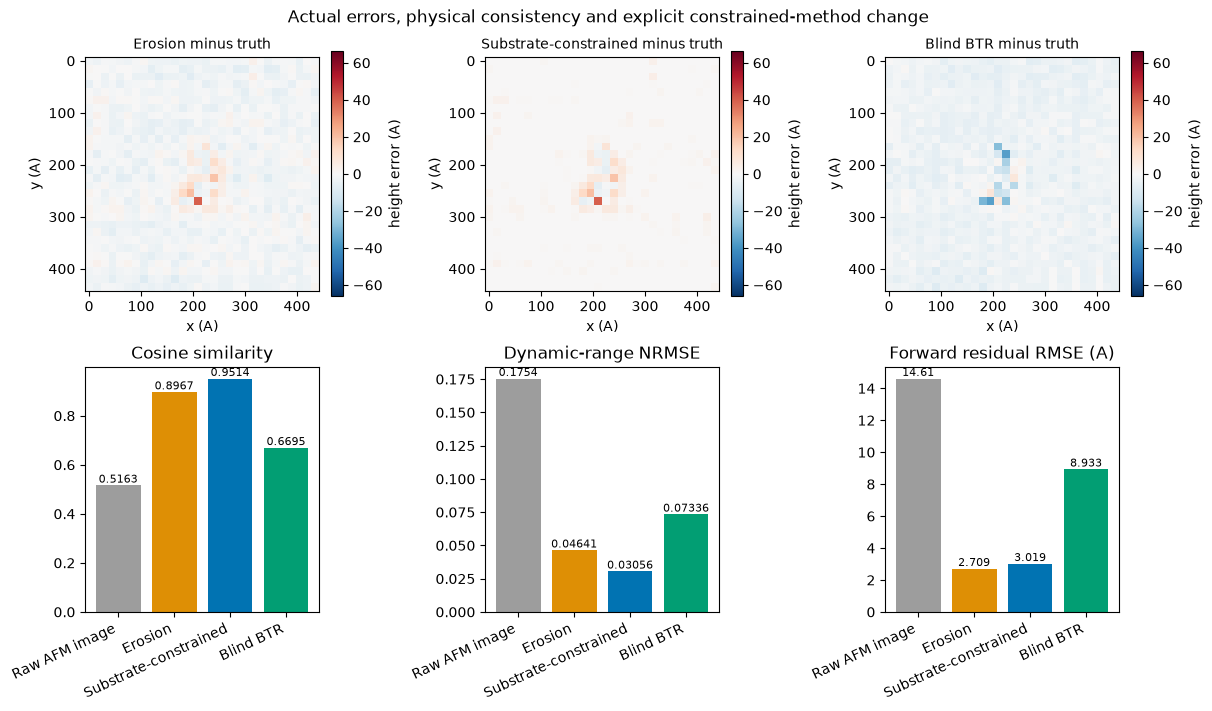

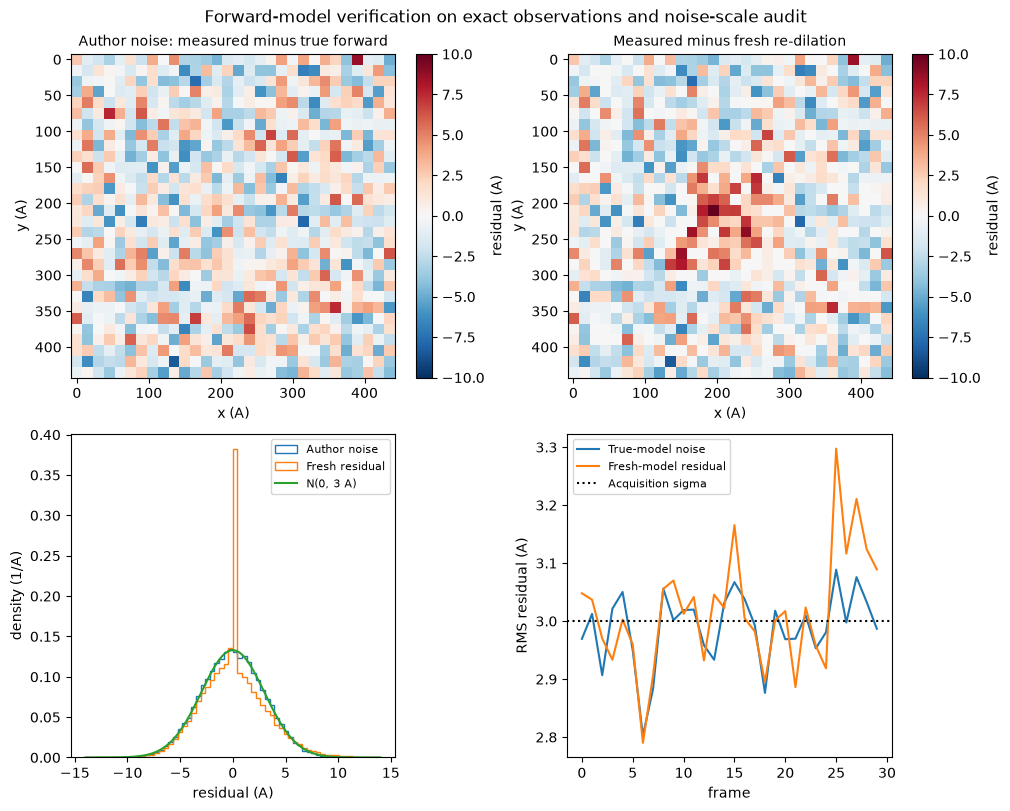

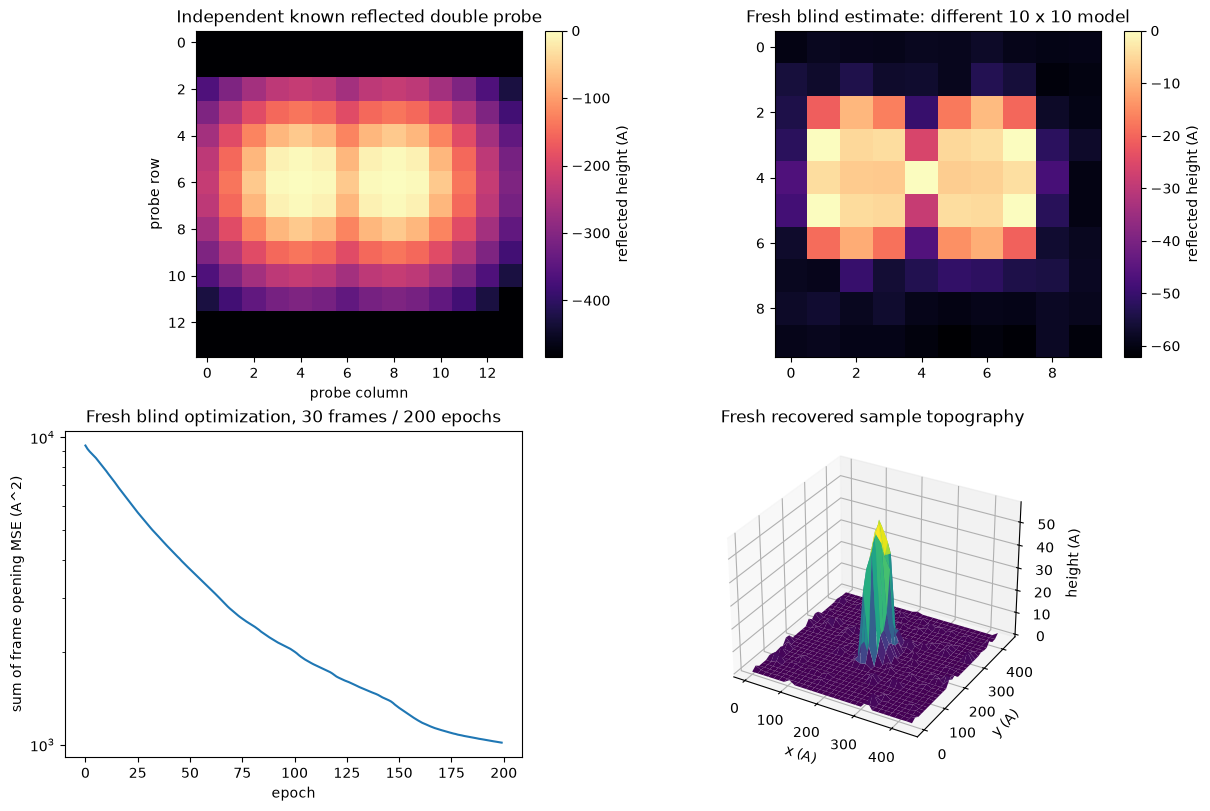

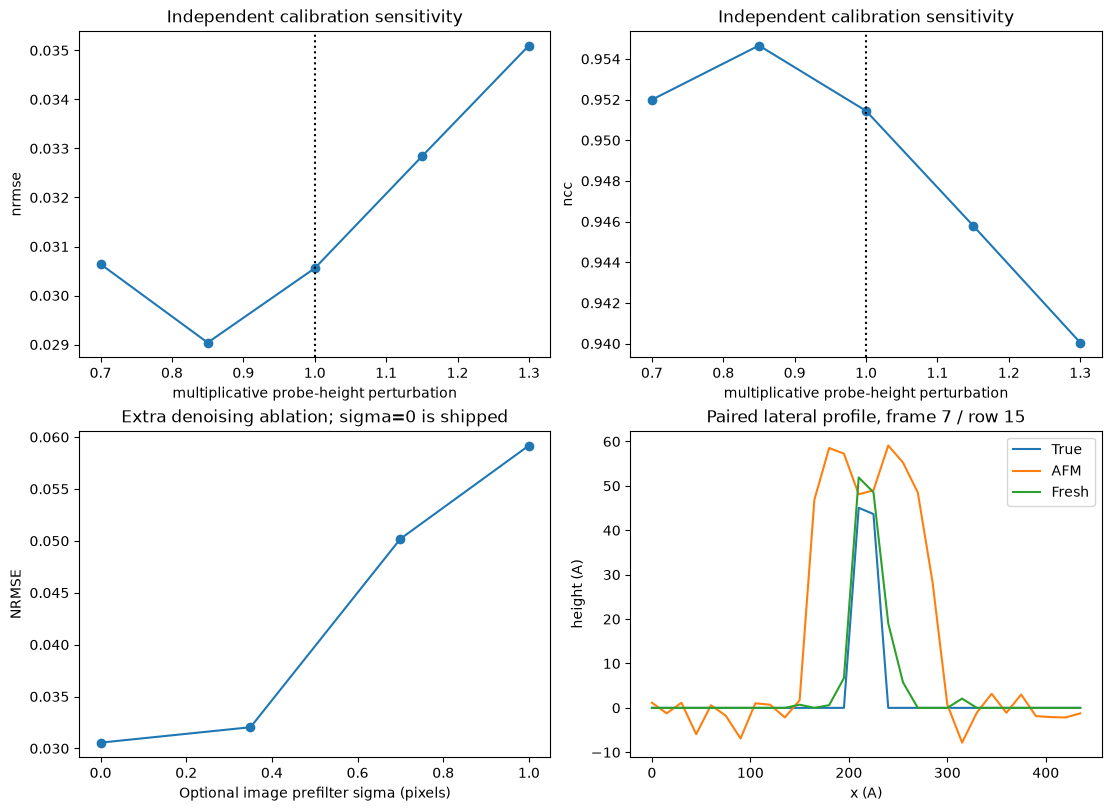

Exported 5 scientific figure groups to D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch5_20261021\material_physics\figures\afm_molecular_surface_height


In [4]:
groups,numeric_sources,metric_table=make_figures(raw,probe,truth,fresh,plain,blind,blind_tip,blind_loss)
print(json.dumps(metric_table,indent=2))
for name,fig in groups:
    display(fig)
    plt.close(fig)
export=os.environ.get('IMAGING_FIGURE_DIR')
if export:
    destination=Path(export);destination.mkdir(parents=True,exist_ok=True)
    for name,fig in groups:
        for extension in ('png','svg','pdf'):
            fig.savefig(destination/(name+'.'+extension),dpi=170,bbox_inches='tight')
    np.savez_compressed(destination/'numeric_sources.npz',**numeric_sources)
    (destination/'metrics.json').write_text(json.dumps(metric_table,indent=2,allow_nan=False),encoding='utf8')
    provenance={'task':'afm_molecular_surface_height','reconstruction_seconds':reconstruction_seconds,'blind_seconds':blind_seconds,'observations_sha256':hashlib.sha256(Path('data/raw_data.npz').read_bytes()).hexdigest(),'figure_groups':len(groups),'fresh_methods':['erosion','nonnegative erosion','blind BTR','probe scale sensitivity','Gaussian prefilter sensitivity'],'files':{f.name:hashlib.sha256(f.read_bytes()).hexdigest() for f in destination.iterdir() if f.is_file()}}
    (destination/'figure_manifest.json').write_text(json.dumps(provenance,indent=2),encoding='utf8')
    print('Exported',len(groups),'scientific figure groups to',destination)

## 6. Conclusion

The retained measurements support known-probe height recovery at the stated noise scale. They do not establish unique molecular structure in probe-inaccessible valleys, experimental AFM accuracy or elastic-contact physics. This documentation change preserves the prior execution evidence without rerunning it.

### Conclusion and limits

The fresh calibrated-probe result reaches cosine NCC about 0.9514 and dynamic-range NRMSE about 0.03056 against the author's actual surfaces, with forward residual RMS about 3.019 Angstrom, consistent with the 3 Angstrom noise. These values are independently recomputed above; they are neither paper-reported measurements nor cached fresh results. The raw erosion and blind-BTR comparisons remain visible.

This is an existing synthetic molecular geometry test, not a claim of experimental AFM accuracy or force-dependent material behavior. Contact is modeled without elastic deformation. Sampling, noise extrema and inaccessible valleys prevent exact surface recovery. Probe perturbations change recovered geometry, and a good contact residual does not establish a unique molecular structure. The original model's physical length unit is Angstrom; a modern general-purpose notebook's nm labels are not copied onto these legacy arrays.
